In [1]:
# Prerequisites
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.figsize"] = (12, 5)

In [2]:
from ponds import PONDS, SIGMOID, Trend, WhiteNoise
import matplotlib.pyplot as plt

/home/lukasro/Documents/TIPMIP/ponds/venv-ponds/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Generating an Abrupt Shift Time Series

### Initializing `PONDS` and Adding Background

`PONDS`' simplest use case is to generate a single time series which is perturbed with some white noise and a backgroud trend. The user can specify the length of the series and parameters for the background. The created class object will contain a data-xarray.Dataset containing a `(time_size x 1 x 1)` time series called `ts`, representing an arbitrary climate variable:

In [3]:
background_noise = 0.05
background_trend = 0.002
background_intercept = 2.5
time_size = 200

pd = PONDS(
    time_size=time_size,
)
pd.add_background(
    background_method=WhiteNoise(
        magnitude=background_noise,
    )
)
pd.add_background(
    background_method=Trend(
        slope=background_trend,
        intercept=background_intercept,
    )
)

pd.data

/home/lukasro/Documents/TIPMIP/ponds/ponds/core.py:118: UserWarning: Shape method specified for a (1x1) grid. PONDS is in single-mode. If chosen shape method is not SINGLE it is likely to fail.
  warnings.warn(


<xarray.Dataset> Size: 3kB
Dimensions:  (time: 200, lat: 1, lon: 1)
Coordinates:
  * time     (time) float64 2kB 0.0 1.0 2.0 3.0 4.0 ... 196.0 197.0 198.0 199.0
  * lat      (lat) float64 8B -90.0
  * lon      (lon) float64 8B -180.0
Data variables:
    ts       (time, lat, lon) float64 2kB 2.501 2.547 2.468 ... 2.892 2.859 2.87
Attributes:
    cluster_key:     c
    background_key:  b

In the output of the cell above, we can see that our created `ponds` store some attributes on the top-level. This indicate prefixes for added background (`background_key`) and shift-cluster (`cluster_key`). <br>

When further investigating the data variable `ts` (click on the two little icons on the right of the row) we can see that the background metadata is stored as its attributes. Each time the class-function `PONDS.add_perturbtation` is called, a new entry is added. This information comes in handy when trying to reproduce the `ponds`.

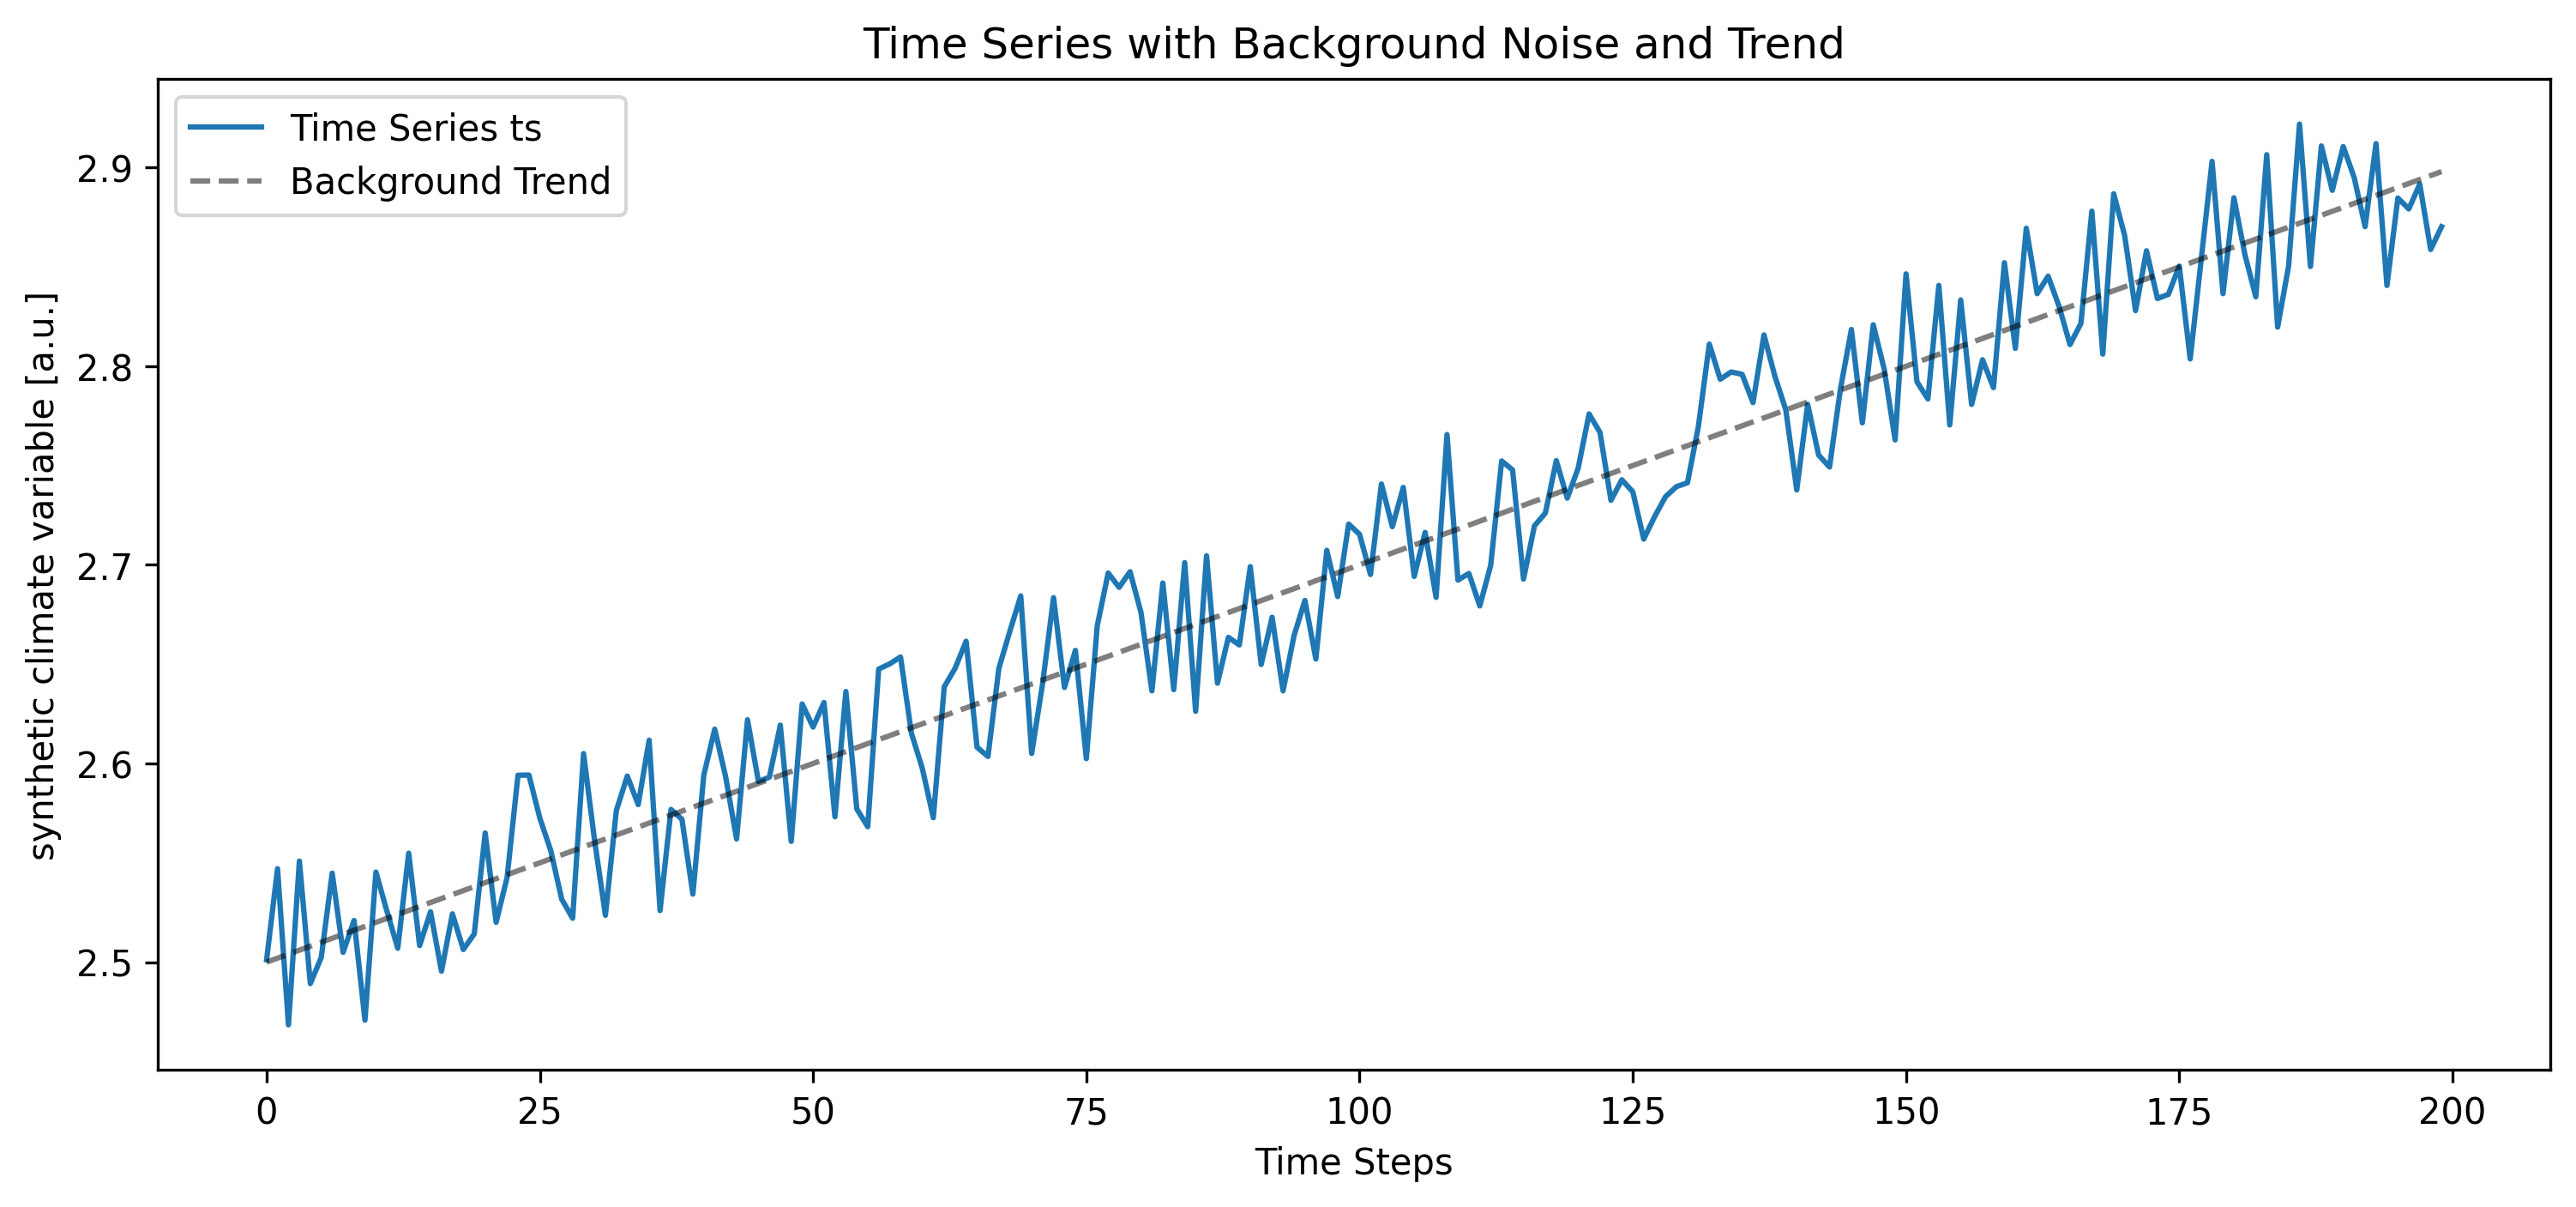

In [4]:
# plot generated time series
pd.data.ts.plot(label="Time Series ts")
# plt.ylim(-0.1, 1.1)

# add background trend
X = np.arange(0, time_size)
plt.plot(
    X,
    background_trend * X + background_intercept,
    linestyle="--",
    label="Background Trend",
    color="black",
    alpha=0.5,
)

# eyecandy
plt.title("Time Series with Background Noise and Trend")
plt.xlabel("Time Steps")
plt.ylabel("synthetic climate variable [a.u.]")
plt.legend()
plt.show()

### Adding Shifts

This time series now can be altered by adding customizable shifts. This is done with the class-function `PONDS.add_shift()`. The simplest version of an abrupt shift is a sigmoid-shift which can be applied by calling `shift_method = SIGMOID()`. In the following example, we add two sigmoid-shifts. The first will use randomly, the second is created with custom chosen variables.

/home/lukasro/Documents/TIPMIP/ponds/ponds/core.py:220: UserWarning: Shape method specified for a (1x1) grid. PONDS is in single-mode. If chosen shape method is not SINGLE it is likely to fail.
  warnings.warn(
/home/lukasro/Documents/TIPMIP/ponds/ponds/core.py:220: UserWarning: Shape method specified for a (1x1) grid. PONDS is in single-mode. If chosen shape method is not SINGLE it is likely to fail.
  warnings.warn(


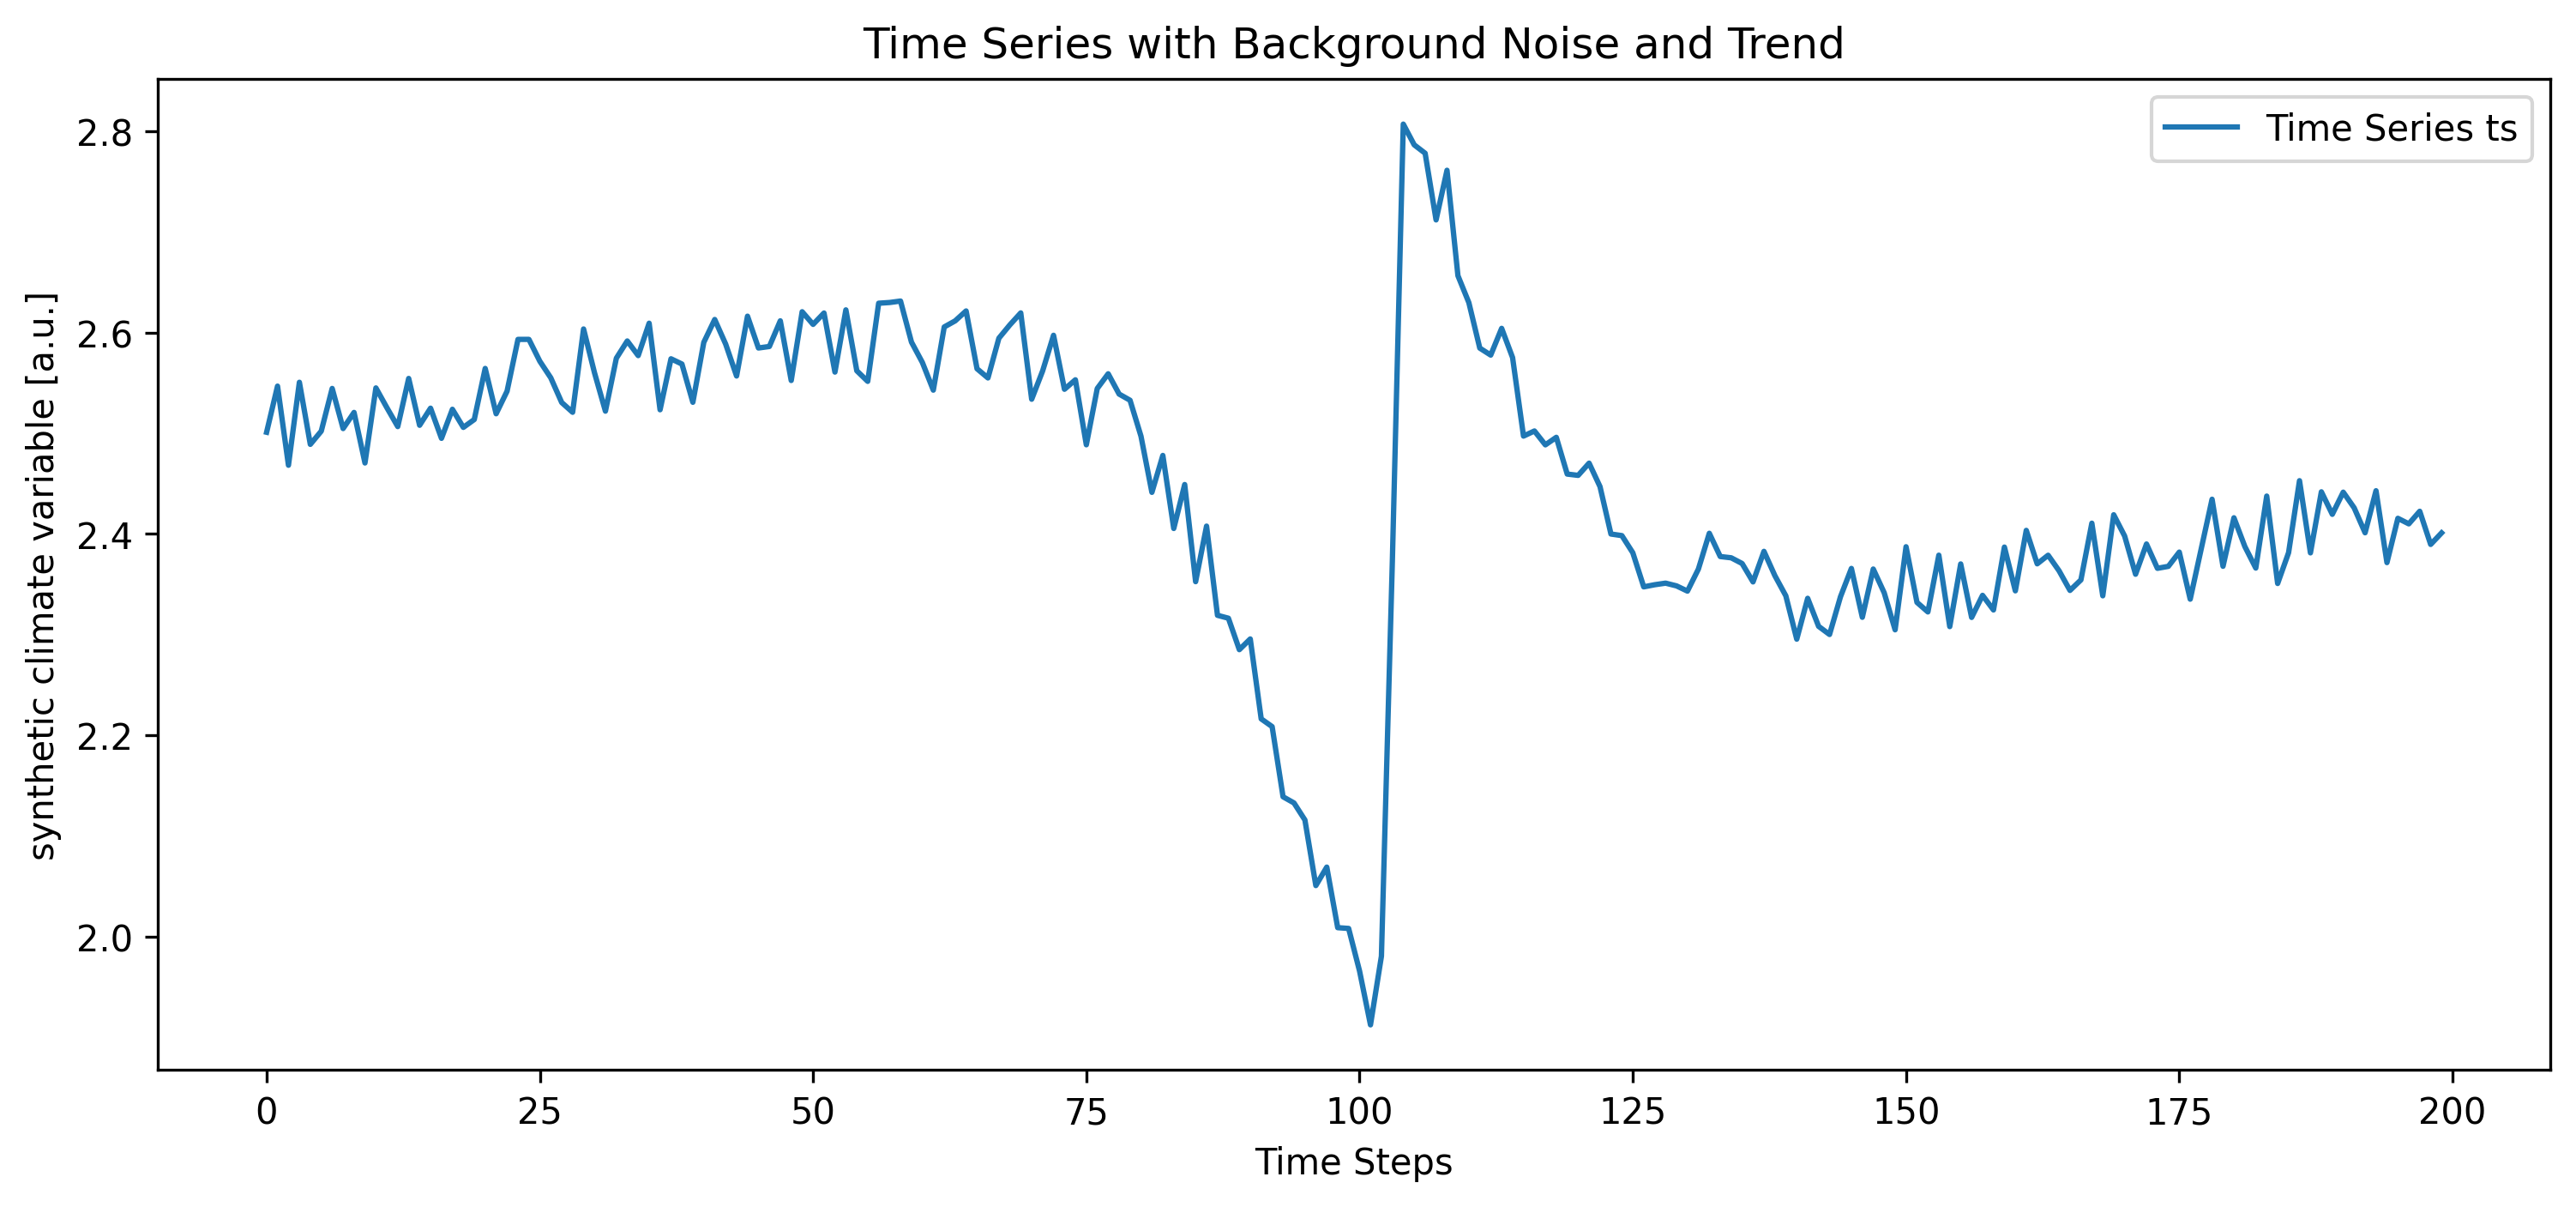

In [5]:
# adding a random shift to the time series
pd.add_shift(
    shift_method=SIGMOID(shift_seed=5),
)

# adding a second, customized shift to the time series
shift_dict = {
    "central_time": 100,  # time step (center) at which the shift occurs
    "shift_magnitude": -1.5,  # magnitude of the shift
    "shift_steepness": 0.1,  # steepness of the sigmoid function
}
pd.add_shift(
    shift_method=SIGMOID(
        **shift_dict,
    ),
)

# plot generated time series
pd.data.ts.plot(label="Time Series ts")

# eyecandy
plt.title("Time Series with Background Noise and Trend")
plt.xlabel("Time Steps")
plt.ylabel("synthetic climate variable [a.u.]")
plt.legend()
plt.show()

## Generating a World Map of Synthetic Data

Using `PONDS` to generate a set of global, synthetic climate data is easy. Like before, we frist create an PONDS class object. This time, we also specify the number of grid points in latitudinal and longitudinal direction. The `PONDS` object is initialised with `(lat_size x lon_size)` grid cells, each containing individual noisy data following a given background trend. <br>

To add one abrupt shift, again, we call the function `PONDS.add_shift()`. This time, in addition to the `shift_method`, we also specify a `shape_method` argument which determines the shape of the ELLIPSIS in the grid. Hence, a spatial blob is generated which acts as a **shift-cluster**. Each grid cell in this cluster contains an abrupt shift of the same kind (**where** is the shift happening). This includes the point in time (**when** is the event happening). A blob clusters similar shift-events in space and time.

In [6]:
from ponds import PONDS, SIGMOID, ELLIPSIS, WhiteNoise
import matplotlib.pyplot as plt

# initialize PONDS object
pd = PONDS(
    lat_size=20,
    lon_size=40,
    time_size=200,
)

# add background with white noise
pd.add_background(
    background_method=WhiteNoise(
        magnitude=0.05,
    )
)

# add random shift
pd.add_shift(
    shape_method=ELLIPSIS(shape_seed=1),
    shift_method=SIGMOID(central_time=25),
)

# add shift with custom parameters
shift_dict = {
    "shift_steepness": 0.2,
    "shift_magnitude": 0.5,
}
pd.add_shift(
    shape_method=ELLIPSIS(shape_seed=4),
    shift_method=SIGMOID(**shift_dict),
)

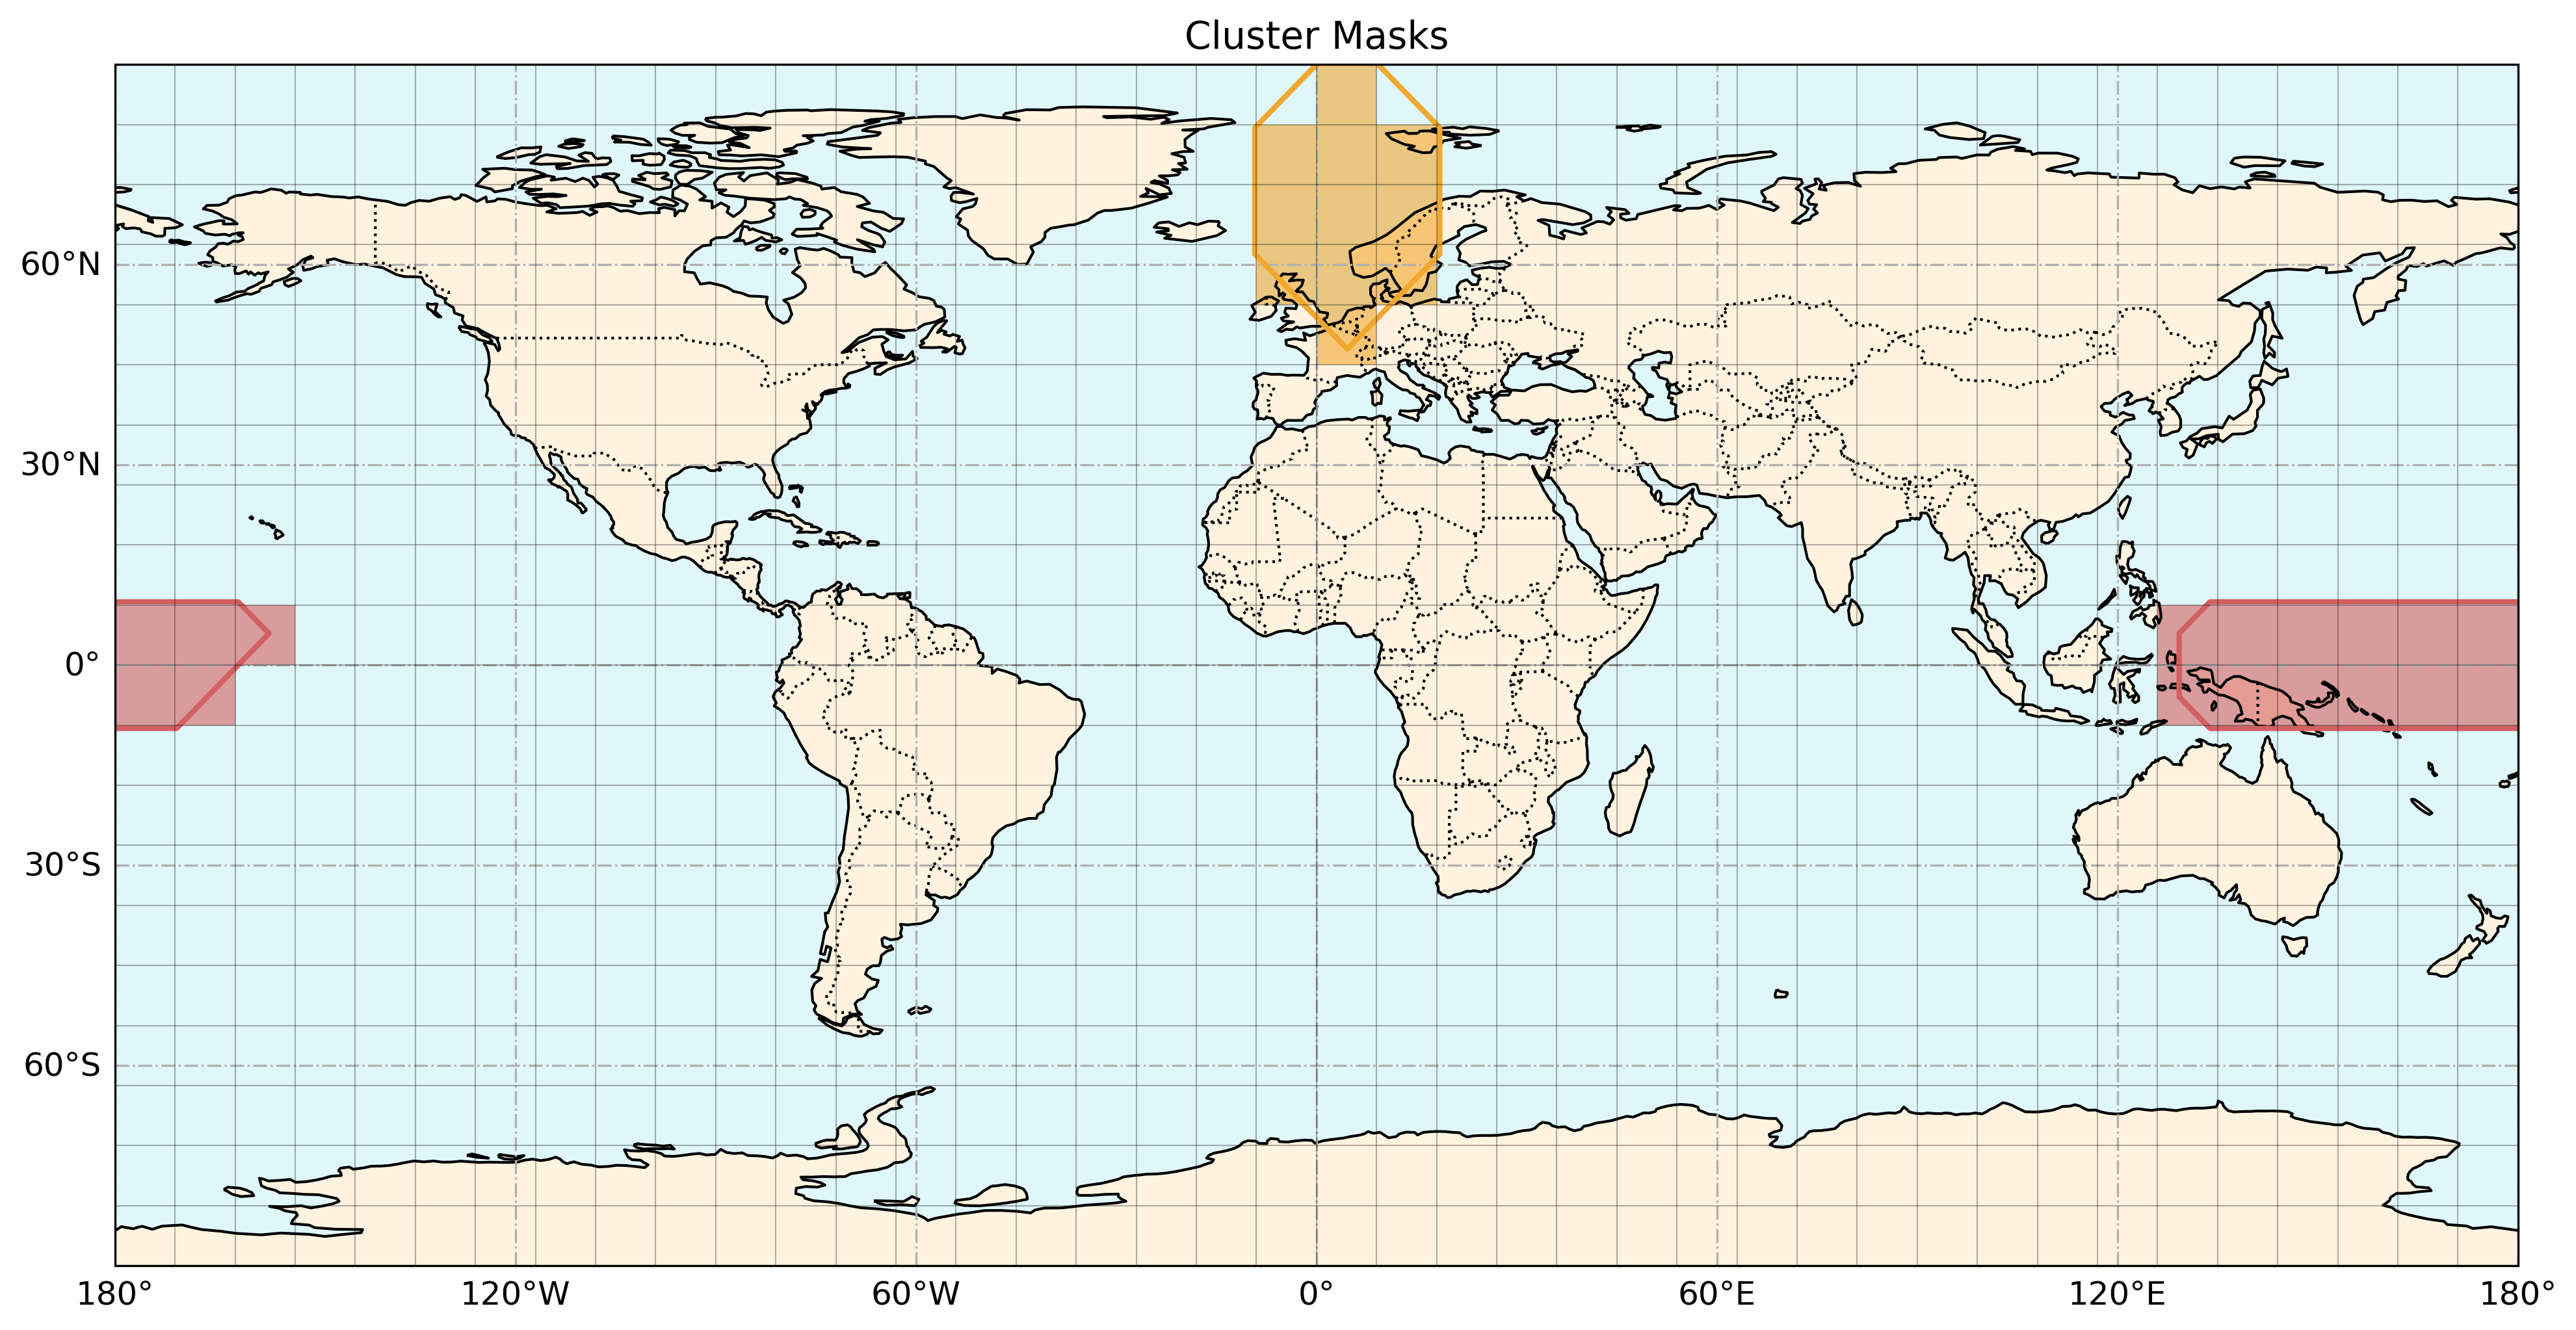

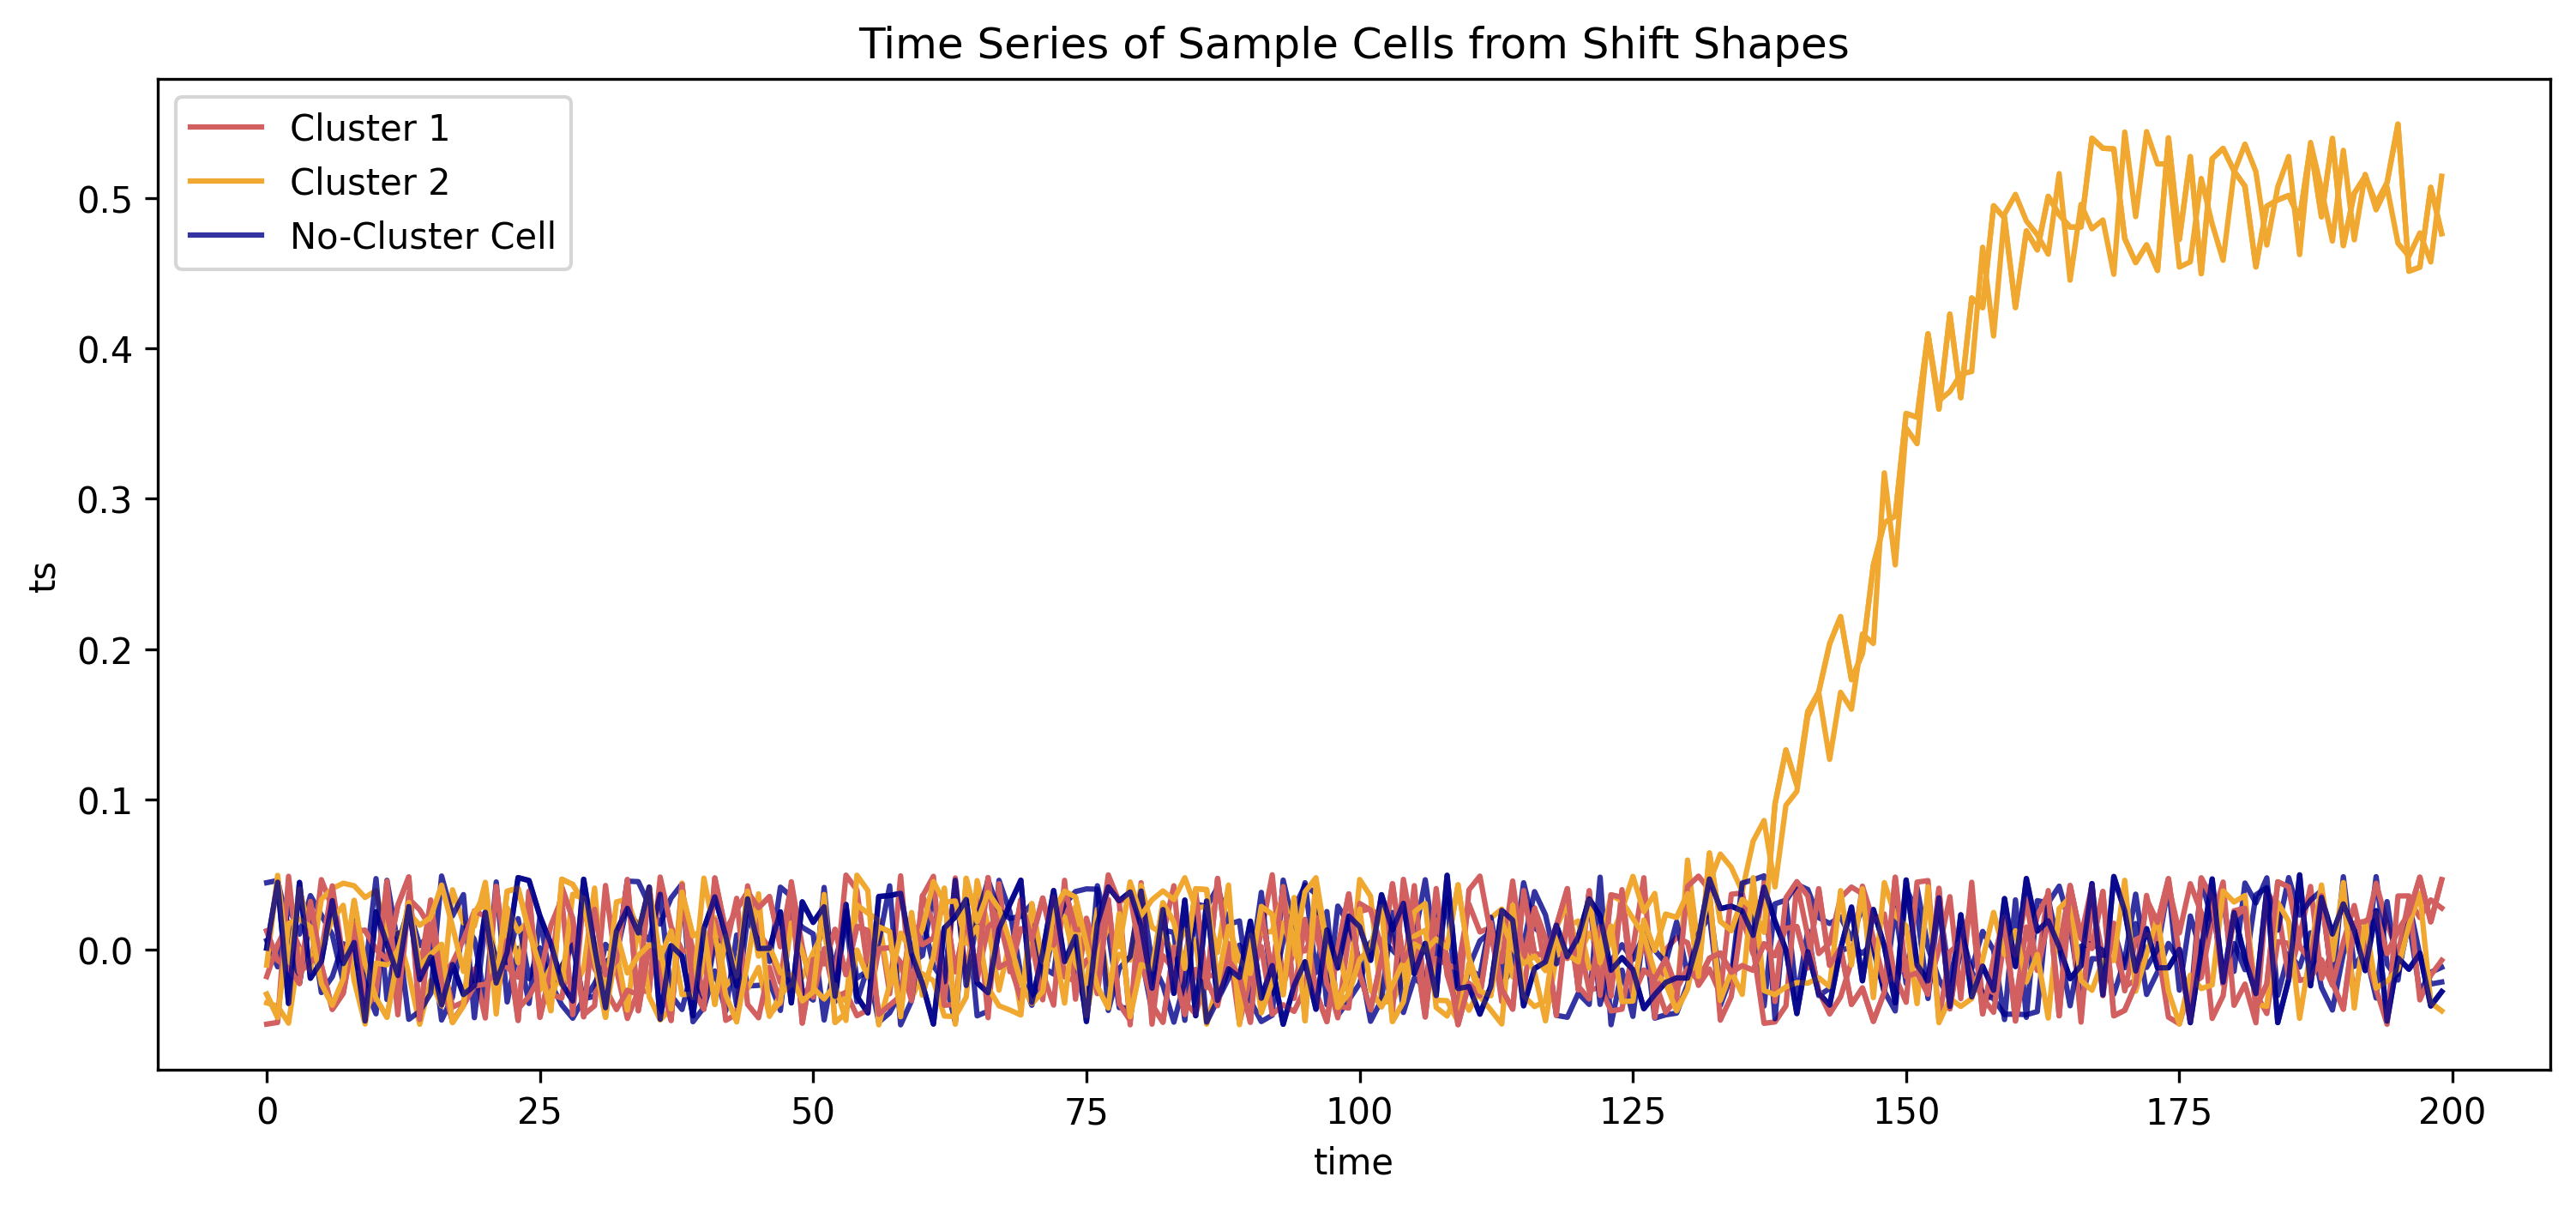

In [7]:
# look at the generated synthetic data
pd.worldmap(show_cells=True)
plt.show()

# plot time series of sample cells
lat1, lon1 = 8, 28  # cell of cluster in indian ocean
lat2, lon2 = 17, 20  # cell of cluster in northern europe
for i in range(3):
    pd.data.ts.isel(lat=0, lon=0 + i).plot.line(x="time", color="darkblue", alpha=0.8)
    pd.data.ts.isel(lat=lat1, lon=lon1 + i).plot.line(x="time", color="#d36060")
    pd.data.ts.isel(lat=lat2, lon=lon2 + i).plot.line(x="time", color="#f0a830")
pd.data.ts.isel(lat=lat1, lon=lon1).plot.line(
    x="time", color="#d36060", label="Cluster 1"
)
pd.data.ts.isel(lat=lat2, lon=lon2).plot.line(
    x="time", color="#f0a830", label="Cluster 2"
)
pd.data.ts.isel(lat=0, lon=0).plot.line(
    x="time", color="darkblue", alpha=0.8, label="No-Cluster Cell"
)

plt.legend()
plt.title("Time Series of Sample Cells from Shift Shapes")
plt.show()

Each added shift is stored as an additional xr.DataArray within the `PONDS.data`. The default name for a shift-cluster is 'c' followed by a running number:

In [8]:
pd.data

<xarray.Dataset> Size: 2MB
Dimensions:  (time: 200, lat: 20, lon: 40)
Coordinates:
  * time     (time) float64 2kB 0.0 1.0 2.0 3.0 4.0 ... 196.0 197.0 198.0 199.0
  * lat      (lat) float64 160B -90.0 -80.53 -71.05 -61.58 ... 71.05 80.53 90.0
  * lon      (lon) float64 320B -180.0 -170.8 -161.5 ... 161.5 170.8 180.0
Data variables:
    ts       (time, lat, lon) float64 1MB 0.001182 0.006205 ... 0.03874 0.00728
    c1       (time, lat, lon) bool 160kB False False False ... False False False
    c2       (time, lat, lon) bool 160kB False False False ... False False False
Attributes:
    cluster_key:     c
    background_key:  b

## Using `PONDS` Data with `TOAD`

PONDS is developed in close proximity to TOAD and is therefore highly compatible with this abrupt shift detection package. Here, we want to demonstrate how a use case could look like.


In [4]:
import matplotlib.pyplot as plt

from ponds import PONDS, ELLIPSIS, SIGMOID, WhiteNoise
from toad import TOAD
from toad.shifts import ASDETECT
from sklearn.cluster import HDBSCAN
from toad.plotting import Plotter

In [7]:
# from ipywidgets import interact
def plot(random_seed=0, n_shifts=1):
    pd = PONDS(
        lat_size=20,
        lon_size=30,
        time_size=200,
    )
    pd.add_background(
        background_method=WhiteNoise(
            magnitude=0.05,
        )
    )

    for n in range(n_shifts):
        print(f">> Adding Shift {n + 1}/{n_shifts}...")
        pd.add_shift(
            shape_method=ELLIPSIS(shape_seed=random_seed + n),
            shift_method=SIGMOID(shift_seed=random_seed + n),
        )

    data_ds = pd.data.ts.to_dataset(name="ts")
    td = TOAD(data_ds)
    td.compute_shifts("ts", ASDETECT())
    td.compute_clusters(
        "ts",
        HDBSCAN(min_cluster_size=10),
        #shifts_filter_func=lambda x: abs(x) > 0.9,
    )

    plt.rcParams["figure.dpi"] = 300

    plotter = td.plotter(
        PlotConfig(
            map_frame=False,
            grid_labels=False,
        )
    )

    plotter.cluster_overview(
        "ts",
        range(10),
        cmap="tab10",
        timeseries_kwargs={},
        map_kwargs={"add_contour": False},
        figsize=(16, 5),
    )

    # Plot true shift locations
    # - Create a list of da_max for all relevant variables
    pd.worldmap(
        title="True Shift Locations",
        shift_type=True,
    )

    # plot cluster timeseries
    fig, axs = plt.subplots(2, 1, figsize=(16, 4))
    plotter.cluster_timeseries("ts", td.get_cluster_ids("ts"), ax=axs[0])

    # plot data timeseries
    td.data.ts.toad.to_timeseries().plot.line(
        x="time", add_legend=False, color="k", alpha=0.1, ax=axs[1]
    )
    axs[0].set_title(f"Cluster {td.get_cluster_ids('ts')} timeseries")
    axs[1].set_title("All data timeseries")
    fig.tight_layout()

In [8]:
plot(random_seed=5, n_shifts=2)

>> Adding Shift 1/2...
>> Adding Shift 2/2...


Shift detection (600 grid cells in 10 blocks): 100%|██████████| 10/10 [00:00<00:00, 86.91it/s]
INFO: New shifts variable ts_dts: min/mean/max=-0.363/0.005/1.000 using 600 grid cells. Skipped 0.0% grid cells: 0 NaN, 0 constant.
INFO: New cluster variable ts_dts_cluster: Identified 0 clusters in 19 pts; Left 100.0% as noise (19 pts).


AttributeError: 'TOAD' object has no attribute 'plotter'

In the first plot we can see the shift-cluster identified by `TOAD`. The second plot shows the true locations of the shift-cluster created by `PONDS`. The last two plots show the location of the shift events in time, first what `TOAD` found and then what `PONDS` created.

## Deleting Features

It might happen that a shift or a background feature is wrongly added or needs to be removed due to any other reason. Deleting features of a ponds object can be achieved by using the respective delete functions.

Lets create a small, arbitrary ponds object with a shift and a background feature:

<xarray.Dataset> Size: 350B
Dimensions:  (time: 5, lat: 3, lon: 2)
Coordinates:
  * time     (time) float64 40B 0.0 1.0 2.0 3.0 4.0
  * lat      (lat) float64 24B -90.0 0.0 90.0
  * lon      (lon) float64 16B -180.0 180.0
Data variables:
    ts       (time, lat, lon) float64 240B 0.01283 -0.004871 ... 1.582 1.584
    c1       (time, lat, lon) bool 30B False False False ... False False False
Attributes:
    cluster_key:     c
    background_key:  b

(-0.1, 1.6)

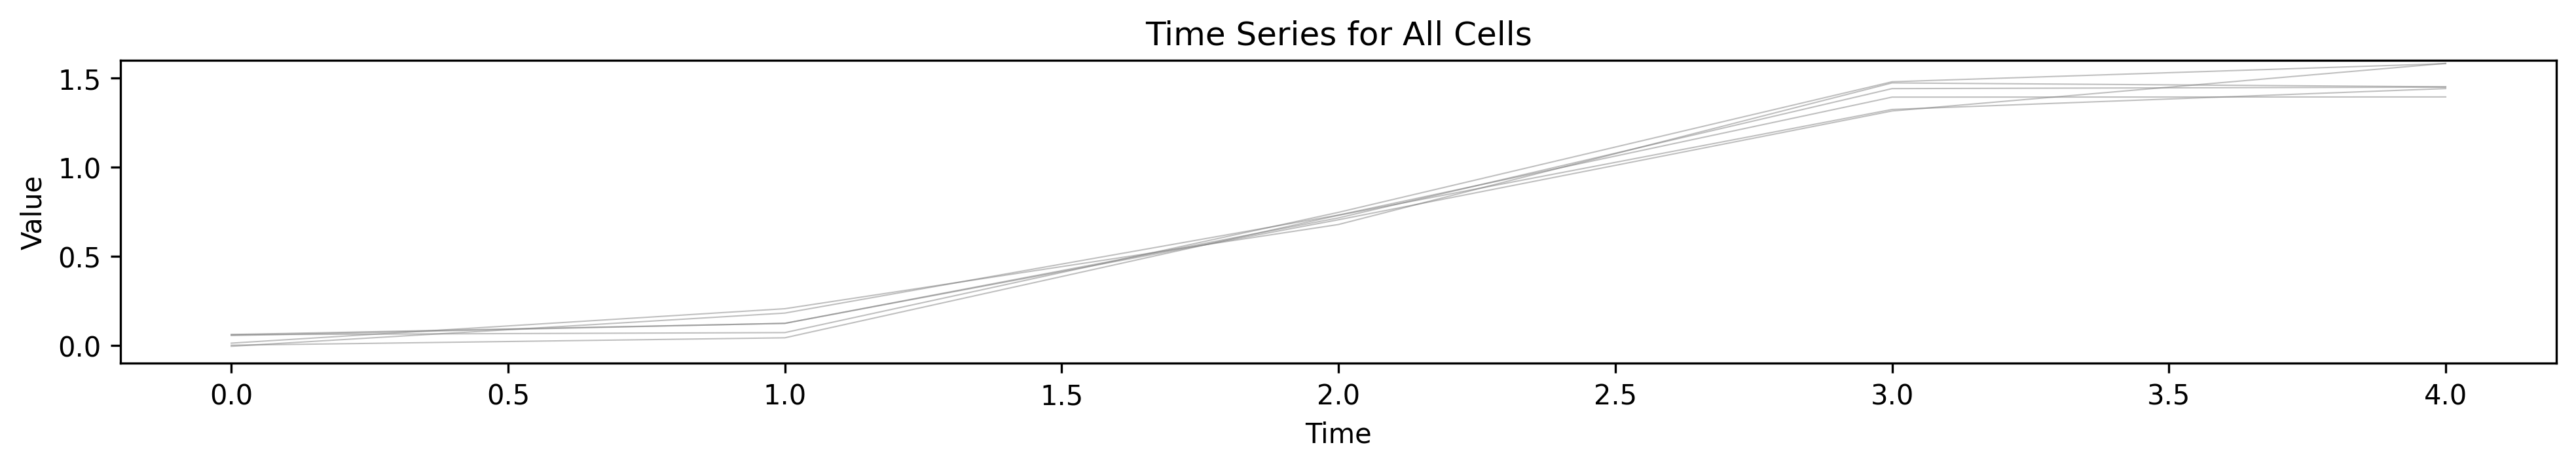

In [9]:
from ponds import PONDS, WhiteNoise, SIGMOID

pd = PONDS(
    lat_size=3,
    lon_size=2,
    time_size=5,
)

pd.add_background(
    background_method=WhiteNoise(
        magnitude=0.1,
        background_seed=1,
    )
)

pd.add_shift(
    shift_method=SIGMOID(
        central_time=2,
        shift_magnitude=1.5,
    ),
)

display(pd.data)
fig, ax = pd.plot_all_ts()
ax.set_ylim(-0.1, 1.6)

When displaying the underlying xarray data container, we can see that the shift was added under the name "c1" and the backgorund was added using "b1" (push on the buttons to the right of the table, at row "ts" to see background attributes).<br>
We can delete these two features easily:

<xarray.Dataset> Size: 320B
Dimensions:  (time: 5, lat: 3, lon: 2)
Coordinates:
  * time     (time) float64 40B 0.0 1.0 2.0 3.0 4.0
  * lat      (lat) float64 24B -90.0 0.0 90.0
  * lon      (lon) float64 16B -180.0 180.0
Data variables:
    ts       (time, lat, lon) float64 240B 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
Attributes:
    cluster_key:     c
    background_key:  b

(-0.1, 1.6)

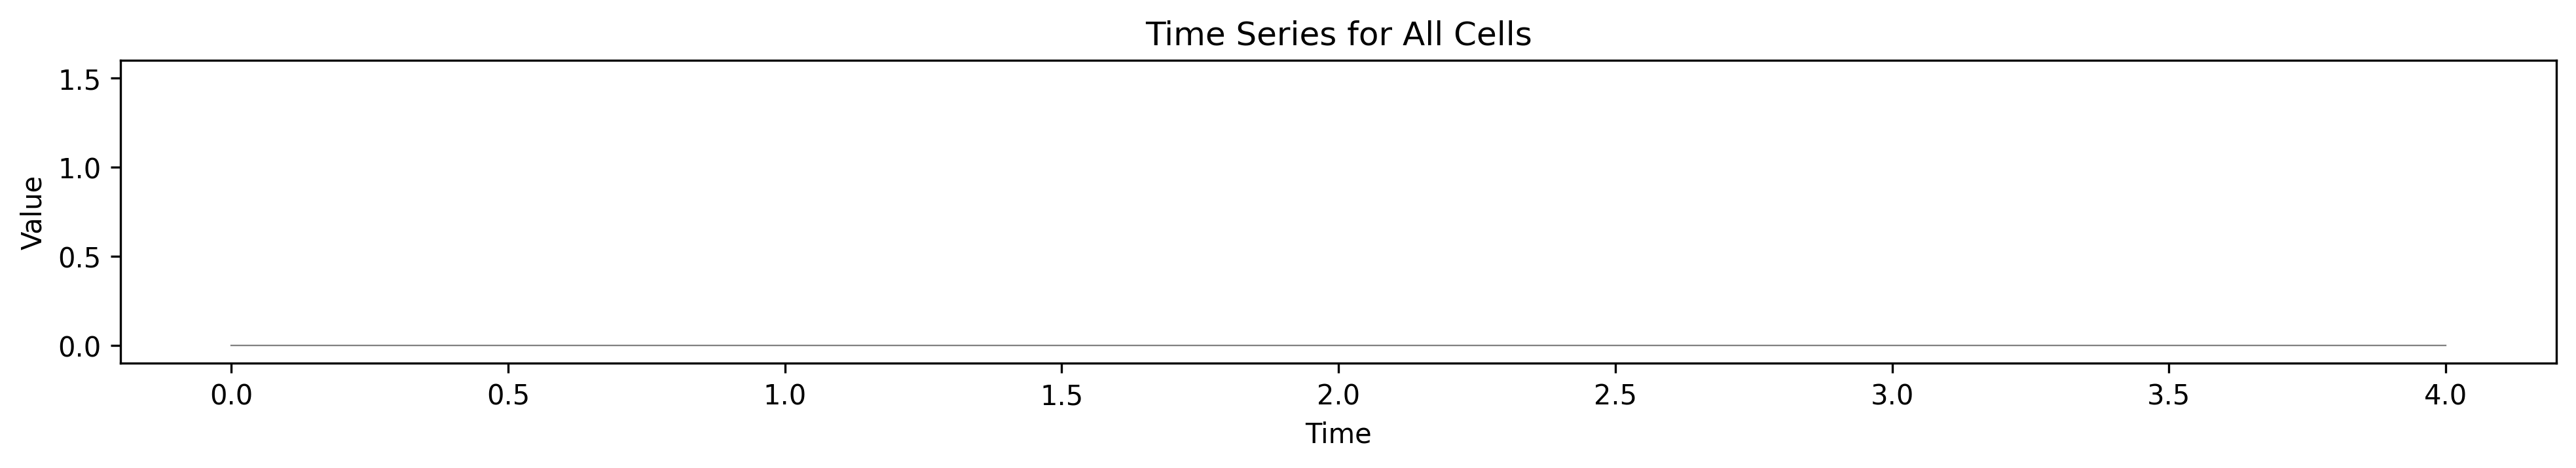

In [10]:
pd.delete_background("b1")
pd.delete_shift("c1")

display(pd.data)
fig, ax = pd.plot_all_ts()
ax.set_ylim(-0.1, 1.6)

## Reproduce an Exact Time Series

`PONDS` is sensetive to reproducibility of a generated dataset to ensure 'lab-conditions' and explainability when benchmarking a detector. This feature might come in handy when the user wants to create surrogates of a given climate event or area. Also, when comparing two PONDS with each other, the metadata stored can help to highlight the differences quicker.<br>Here, we want to show how a dataset can be reproduced by using the metadata stored within the ponds object.

General metadata for the underlying, noisy time series is stored on a `xarray.Dataset` level.

In [11]:
from ponds import PONDS

# create an arbitrary PONDS object
pd = PONDS(
    lat_size=200,
    lon_size=300,
    time_size=200,
)

# get PONDS parameters as dictionary
ponds_dict = pd.get_ponds_dict()
print(f"PONDS Parameters:\n>> {ponds_dict}")

PONDS Parameters:
>> {'lat_size': 200, 'lon_size': 300, 'time_size': 200, 'cluster_key': 'c'}


By pluging this ponds-dictionary into a newly generated ponds-object, we expect to receive the exact same dataset.

In [12]:
# Recreate PONDS object from dictionary
pd_rep = PONDS(**ponds_dict)

# check if the time series are equal
print(f"Are the generated time series equal?\n>> {pd.data.ts.equals(pd_rep.data.ts)}")

Are the generated time series equal?
>> True


The same logic goes for ponds where some background or a shift is added. Here, we need to extract the metadata on a cluster level, which corresponds to an `xarray.DataArray` with the stored cluster mask.

In [13]:
from ponds import Trend, ELLIPSIS

# add background trend to the PONDS object
pd.add_background(
    background_method=Trend(),
    shape_method=ELLIPSIS(),
)

# get background parameters as instances
b1_instance, sb1_instance = pd.get_background_instance("b1")
print(f"Background Instance b1:\n>> {b1_instance}")
print(f"Background Instance sb1:\n>> {sb1_instance}")

Background Instance b1:
>> <ponds.backgroundgen.Trend object at 0x72ba68690d50>
Background Instance sb1:
>> <ponds.shapegen.ELLIPSIS object at 0x72ba68620c50>


In [14]:
from ponds import ELLIPSIS, SIGMOID

# add a shift to the original PONDS object
pd.add_shift(
    shape_method=ELLIPSIS(shape_seed=2),
    shift_method=SIGMOID(shift_seed=3),
)

# get shift cluster parameters
shift_instance, shape_instance, correlation_instance = pd.get_cluster_instance("c1")
print(f"Shape Parameters:\n>> {shape_instance}")
print(f"Shift Parameters:\n>> {shift_instance}")

Shape Parameters:
>> <ponds.shapegen.ELLIPSIS object at 0x72ba686218d0>
Shift Parameters:
>> <ponds.shiftgen.SIGMOID object at 0x72ba6869c4d0>


In [15]:
# adding the same background to the replica
pd_rep.add_background(
    background_method=b1_instance,
    shape_method=sb1_instance,
)

# adding the same shifts to the replica
pd_rep.add_shift(
    shape_method=shape_instance,
    shift_method=shift_instance,
    correlation_method=correlation_instance,
)

# check if the time series are still equal
print(f"Are the generated time series equal?\n>> {pd.data.ts.equals(pd_rep.data.ts)}")

Are the generated time series equal?
>> True


## Writing and Reading Files

Currently, PONDS only support NetCDF4 file formats for writing and reading. Here, we demonstrate how a created PONDS can be saved and loaded locally.

In [16]:
from ponds import PONDS, SIGMOID, ELLIPSIS, WhiteNoise

pd = PONDS(
    lat_size=10,
    lon_size=10,
    time_size=10,
)
pd.add_background(background_method=WhiteNoise())
pd.add_shift(
    shift_method=SIGMOID(),
    shape_method=ELLIPSIS(),
)

# save file
pd.save("dummy.nc")

In [17]:
# read the file back
pd_read = PONDS.load("dummy.nc")

# check if the read data matches the original data
print(
    f"Is the loaded file identical to the original?\n>> {pd.data.equals(pd_read.data)}"
)

Is the loaded file identical to the original?
>> True
